# Fields: one geometry per group of runs

A tiling spreads its runs over tens of degrees. The tiles of `sim_tiling` (S250328ae) lie in a patch near
RA 144, Dec +9, spanning about 4 deg in RA and 9 deg in Dec, one run per tile (4 tiles in all). `uuls.fields` splits the runs
into fields instead: pointings closer than a linking length share a field, and each field gets its own small
geometry, its own GW map on that geometry and its own reduced data. The global statistic is

$$\Lambda = \max_{f} \; \max_{b \in \mathrm{ROI}_f} \left( TS_b + 2 \ln p_b \right),$$

with $TS_b$ and $p_b$ computed on the grid and data of field $f$, and $\mathrm{ROI}_f$ the bins of the GW 95%
credible region that field $f$ observes (exposure > 0 inside the safe mask, `lambda_stat.roi`). This notebook shows the fields of the tiling
case, the maps of one field, how overlapping fields are treated, and the background-only distribution of
$\Lambda$ for one field and for several fields made from the same runs.

Inputs: `configs/cases/sim_tiling.yaml` (tilepy tiling in `cache/tilepy_2d/<key>`, about one minute if
missing; GW maps of its fields in `cache/gwmap/<key>`, about 90 s if missing); the four background-only wobble
runs of `03_simulated_data` (`outputs/results/0_tools/03_simulated_data/`, `cache/simulst_dl3/<key>`), reduced
per field into `cache/reduce/<key>` with the background setting of `configs/cases/sim_wobble.yaml`;
background-only realisations in `cache/realisations_fields/<key>`, with the ROI and with the GW mask alone. The cells print the keys they load.

In [1]:
import json
import warnings
warnings.filterwarnings("ignore", "Wswiglal-redir-stdio")

import astropy.units as u
import healpy as hp
import matplotlib.pyplot as plt
import numpy as np
from astropy.coordinates import SkyCoord
from astropy.table import Table
from gammapy.maps import WcsGeom
from ligo.skymap.io import read_sky_map

from uuls import cases, fields, gwmap, paths, pointings, realisations, simdata
from uuls.figures import COLORS, FigureSaver

figs = FigureSaver("0_tools", "06_fields")

## The fields of the tiling case

The case config limits tilepy to 55 deg zenith and counts a disc of 2.0 deg radius per tile (the radius to which
the present simulst IRFs give exposure). The tiles are then split with the linking length of the config,
`analysis.fields.link_deg` = 1 deg, and each field gets a square geometry with the common 0.08 deg bins, wide
enough to hold its runs out to the 2.5 deg offset-max of the reduction. There is no DL3 for this case yet, so
the fields carry a geometry and a GW map but no reduced data.

In [2]:
case = cases.load_case("sim_tiling")
tiles = case.pointings()
FOV = case.pointing["settings"]["FOV"]
tiling = fields.build_fields(case)
sep = pointings.coords(tiles)[:, None].separation(pointings.coords(tiles)[None, :]).deg
print(f"{len(tiles)} tiles, {len(tiling)} fields; closest pair of tiles {sep[sep > 0].min():.2f} deg apart")
rows = []
for f in tiling:
    ny, nx = f.geom.to_image().data_shape
    rows.append({"field": f.name, "runs": ",".join(map(str, f.obs_ids)), "RA": f.center.ra.deg,
                 "Dec": f.center.dec.deg, "bins": f"{nx} x {ny}", "p in geometry": f.gwmap.prob.sum(),
                 "GW-region bins": int(f.gwmap.mask.sum())})
field_table = Table(rows=rows)
for c in ("RA", "Dec"):
    field_table[c].format = ".2f"
field_table["p in geometry"].format = ".3f"
field_table

[cache] tilepy_2d/aee506ef8148: loaded
[cache] tilepy_2d/aee506ef8148: loaded
[cache] gwmap/781b87740664: loaded
[cache] gwmap/34cd0735cbcc: loaded
[cache] gwmap/c4210b10ea8f: loaded
[cache] gwmap/a471e512ee31: loaded
4 tiles, 4 fields; closest pair of tiles 2.35 deg apart


field,runs,RA,Dec,bins,p in geometry,GW-region bins
str6,str1,float64,float64,str7,float64,int64
field0,1,144.84,11.11,63 x 63,0.817,1815
field1,2,143.44,7.48,63 x 63,0.280,1300
field2,3,146.60,13.86,63 x 63,0.375,1051
field3,4,142.38,5.38,63 x 63,0.094,810


The fields on the skymap: probability density, the 50% and 90% contours, the disc of radius 2.0 deg that tilepy
counted for each tile, and the square geometry of each field. The geometries are wider than the discs because
the reduction keeps events out to 2.5 deg offset.

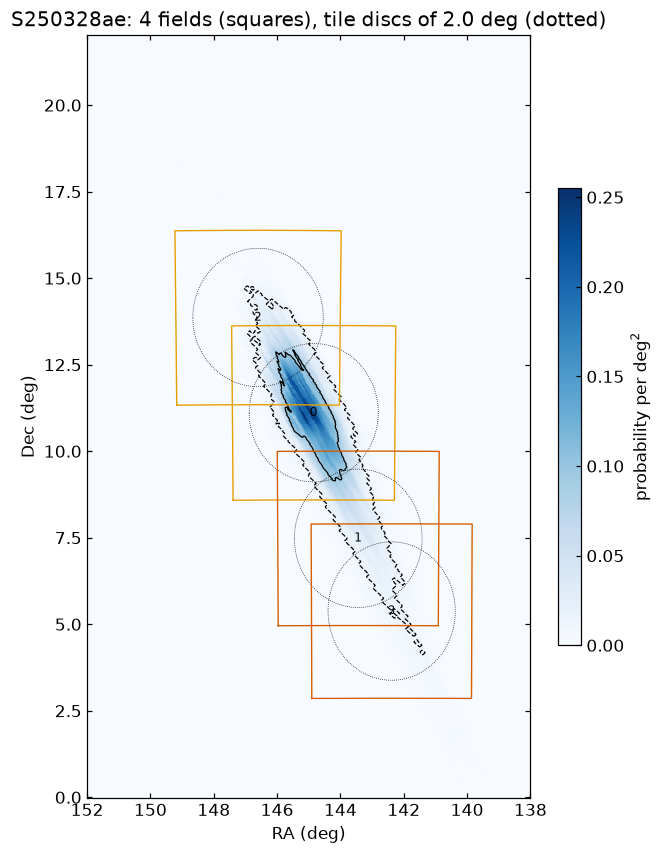

In [3]:
prob_hp, _ = read_sky_map(str(case.skymap), moc=False, nest=True, distances=False)
nside = hp.npix2nside(len(prob_hp))
order = np.argsort(prob_hp)[::-1]
cl = np.empty_like(prob_hp)
cl[order] = np.cumsum(prob_hp[order])                 # credible level of each pixel

ra_g, dec_g = np.linspace(138, 152, 421), np.linspace(0, 22, 821)
RA, DEC = np.meshgrid(ra_g, dec_g)
ipix = hp.ang2pix(nside, RA, DEC, nest=True, lonlat=True)
dens = prob_hp[ipix] / hp.nside2pixarea(nside, degrees=True)
phi = np.linspace(0, 2 * np.pi, 200)


def outline(geom, n=40):
    # RA, Dec (deg) along the outer edge of a geometry's image
    image = geom.to_image()
    ny, nx = image.data_shape
    s = np.linspace(0, 1, n)
    x0, x1, y0, y1 = -0.5, nx - 0.5, -0.5, ny - 0.5
    x = np.concatenate([x0 + (x1 - x0) * s, np.full(n, x1), x1 - (x1 - x0) * s, np.full(n, x0)])
    y = np.concatenate([np.full(n, y0), y0 + (y1 - y0) * s, np.full(n, y1), y1 - (y1 - y0) * s])
    lon, lat = image.pix_to_coord((x, y))
    return u.Quantity(lon, u.deg).value, u.Quantity(lat, u.deg).value


fig, ax = plt.subplots(figsize=(6.5, 9))
im = ax.pcolormesh(RA, DEC, dens, cmap="Blues", shading="auto", rasterized=True)
ax.contour(RA, DEC, cl[ipix], levels=[0.5, 0.9], colors="k", linestyles=["-", "--"], linewidths=0.8)
for k, f in enumerate(tiling):
    ax.plot(*outline(f.geom), color=COLORS[k % 2 * 2 + 1], lw=0.9)
    r = f.pointings[0]
    ax.plot(r["ra"] + FOV * np.cos(phi) / np.cos(np.radians(r["dec"])), r["dec"] + FOV * np.sin(phi),
            color="k", lw=0.5, ls=":")
    ax.text(f.center.ra.deg, f.center.dec.deg, str(k), ha="center", va="center", fontsize=8)
ax.set_xlim(ra_g.max(), ra_g.min())
ax.set_xlabel("RA (deg)")
ax.set_ylabel("Dec (deg)")
ax.set_title(f"S250328ae: {len(tiling)} fields (squares), tile discs of {FOV} deg (dotted)")
fig.colorbar(im, ax=ax, label="probability per deg$^2$", shrink=0.6)
figs.save(fig, "fields_on_sky")
plt.show()

## One field

The GW map of the first field (the first tile, which holds the most probability) on its own grid, and the
number of field geometries that contain each bin. The 95% region of S250328ae: 9231 of its pixels are
inside field0 and 14832 are inside two or more of the four fields, so the outline clips part of the field.
With data, the ROI of the field is
this region cut down to the bins its run exposes (shown below on the wobble example). The strips at the top and bottom are shared with the neighbouring fields
(dotted: the 2.0 deg discs of the neighbouring tiles).

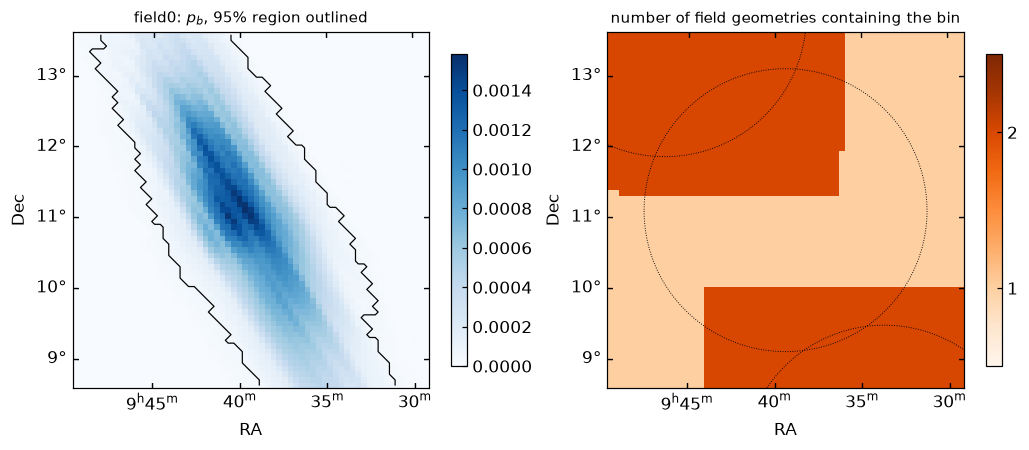

In [4]:
f0 = tiling[0]
cover0 = fields.coverage(tiling, f0.geom)
wcs0 = f0.geom.to_image().wcs
fig = plt.figure(figsize=(11.5, 4.6))
ax = fig.add_subplot(1, 2, 1, projection=wcs0)
im = ax.imshow(f0.gwmap.prob, origin="lower", cmap="Blues")
ax.contour(f0.gwmap.mask, levels=[0.5], colors="k", linewidths=0.8)
ax.set_title(f"{f0.name}: $p_b$, 95% region outlined", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.8)
ax = fig.add_subplot(1, 2, 2, projection=wcs0)
im = ax.imshow(cover0, origin="lower", cmap="Oranges", vmin=0.5, vmax=cover0.max() + 0.5)
for f in tiling:
    r = f.pointings[0]
    ax.plot(r["ra"] + FOV * np.cos(phi) / np.cos(np.radians(r["dec"])), r["dec"] + FOV * np.sin(phi),
            color="k", lw=0.6, ls=":", transform=ax.get_transform("icrs"))
ax.set_xlim(-0.5, cover0.shape[1] - 0.5)
ax.set_ylim(-0.5, cover0.shape[0] - 0.5)
ax.set_title("number of field geometries containing the bin", fontsize=10)
fig.colorbar(im, ax=ax, shrink=0.8, ticks=range(1, cover0.max() + 1))
for a in fig.axes[::2]:
    a.coords[0].set_axislabel("RA")
    a.coords[1].set_axislabel("Dec")
figs.save(fig, "one_field_gw")
plt.show()

## Overlapping fields

Neighbouring tiles share sky, so a position can be inside two or three field geometries. Two ways to deal with
that were considered: merge overlapping fields into one, or leave them and let a position be a trial in every
field that contains it. Merging means linking pointings at the scale of the geometries (two runs exposed to
2.5 deg overlap when they are less than 5 deg apart). The cell below shows what that does to this tiling.

In [5]:
for link in (1.0, 2.5, 5.0):
    groups = fields.split_fields(tiles, link_deg=link)
    print(f"link {link:3.1f} deg: {len(groups):2d} fields, largest has {max(len(g) for g in groups):2d} runs")

link 1.0 deg:  4 fields, largest has  1 runs
link 2.5 deg:  3 fields, largest has  2 runs
link 5.0 deg:  1 fields, largest has  4 runs


Merging collapses the four fields back into one, the large geometry the split was meant to avoid. The rule
used is therefore the second one: overlaps stay, and $\Lambda$ is the maximum over fields. It is correct for
three reasons. The fields partition the runs, so the counts of two fields are independent data, and in an
overlap the two values of $TS_b$ are two independent looks at the same position. $\Lambda$ is a maximum, not a
sum, so a position inside two fields does not have its GW probability added twice. And the Monte Carlo
(`realisations.run_fields`) uses the same rule: one source drawn on the sky, injected into every field whose
geometry contains it, each field faked from its own runs, $\Lambda$ the maximum over fields. The distribution
of $\Lambda$, with or without signal, is calibrated on the statistic used on the data, and the extra trials in
the overlaps are present in both. What the rule gives up is the combination of runs in an overlap: there the
sensitivity is that of the better field, not of the two together, so the limit can only be a little higher
(conservative).

The amount of sky and probability involved, counted on the HEALPix pixels of the 99% region: the probability
inside no field, inside exactly one, and inside two or more field geometries. The sum over fields of the
probability in each geometry exceeds the probability of their union by the doubly covered part; the injection
sampler draws on the HEALPix map, so it counts each position once.

In [6]:
sel = np.flatnonzero(cl <= 0.99)
ra_p, dec_p = hp.pix2ang(nside, sel, nest=True, lonlat=True)
pix = SkyCoord(ra_p, dec_p, unit="deg")
n_cover = fields.coverage(tiling, pix)
p = prob_hp[sel]
print(f"probability in the 99% region:              {p.sum():.3f}")
print(f"  inside no field geometry:                  {p[n_cover == 0].sum():.3f}")
print(f"  inside exactly one:                        {p[n_cover == 1].sum():.3f}")
print(f"  inside two or more:                        {p[n_cover >= 2].sum():.3f}")
print(f"sum over fields of p in the geometry:        {sum(f.gwmap.prob.sum() for f in tiling):.3f}")
print(f"probability of the union of the geometries:  {p[n_cover > 0].sum():.3f}")

probability in the 99% region:              0.990
  inside no field geometry:                  0.009
  inside exactly one:                        0.398
  inside two or more:                        0.584
sum over fields of p in the geometry:        1.565
probability of the union of the geometries:  0.981


## A small example with data: four wobble runs as one field or as four

The tiling case has no simulated data yet, so the effect of the rule on $\Lambda$ is shown on the four
background-only wobble runs of `03_simulated_data` (S240615dg, 0.4 deg offsets), simulated with the simulst
production `2025_2p5` (IRFs and exposure out to 2.5 deg offset). With the default linking length they form one
field. With a linking length of 0.3 deg, shorter than the 0.57 deg between neighbouring wobbles, each run
becomes its own field: four geometries that overlap almost completely, each holding a quarter of the data. This
is the extreme case of overlap. Both versions are reduced with the background of `sim_wobble.yaml` (`fov`: the
run's background model, normalisation fitted per run). The first run is also simulated with the older
production `2025`, whose exposure stops at 1.2 deg, to show the region of interest where it matters.

In [7]:
inputs = paths.RESULTS / "0_tools" / "03_simulated_data"
point = pointings.read(inputs / "pointings.ecsv")
sim = json.loads((inputs / "simulation.json").read_text())
skymap_wob = paths.GW_SKYMAPS / "S240615dg.fits"
settings = cases.load_case("sim_wobble").analysis["reduce"]
print("reduce settings:", settings)
dl3_bkg = simdata.simulate(point, nsb=sim["nsb"], seed=sim["seed"], production="2025_2p5")
one = fields.build_fields(point, dl3_bkg, settings, skymap=skymap_wob, link_deg=1.0, verbose=True)
four = fields.build_fields(point, dl3_bkg, settings, skymap=skymap_wob, link_deg=0.3, verbose=True)
dl3_short = simdata.simulate(point[:1], nsb=sim["nsb"], seed=sim["seed"], production="2025")
short = fields.build_fields(point[:1], dl3_short, settings, skymap=skymap_wob, verbose=True)
for label, fs in (("one", one), ("four", four), ("run 1, production 2025", short)):
    print(f"{label}: " + "; ".join(f"{f.name} runs {f.obs_ids}, {f.geom.to_image().data_shape[1]} bins wide"
                                   for f in fs))

reduce settings: {'background': 'fov'}


RuntimeError: simulst job failed (status 1), log /home/jjimenezq/projects/uncertain-uls/cache/simulst_dl3/33cf7015fe2d/simulst.log:
Traceback (most recent call last):
  File "/home/jjimenezq/projects/uncertain-uls/scripts/simulst_job.py", line 44, in <module>
    from simulst.background.library import BackgroundLibrary
ModuleNotFoundError: No module named 'simulst'


The maps of the single field: counts and fitted background summed over energy, exposure at 1 TeV, and the GW
probability with its 95% region.

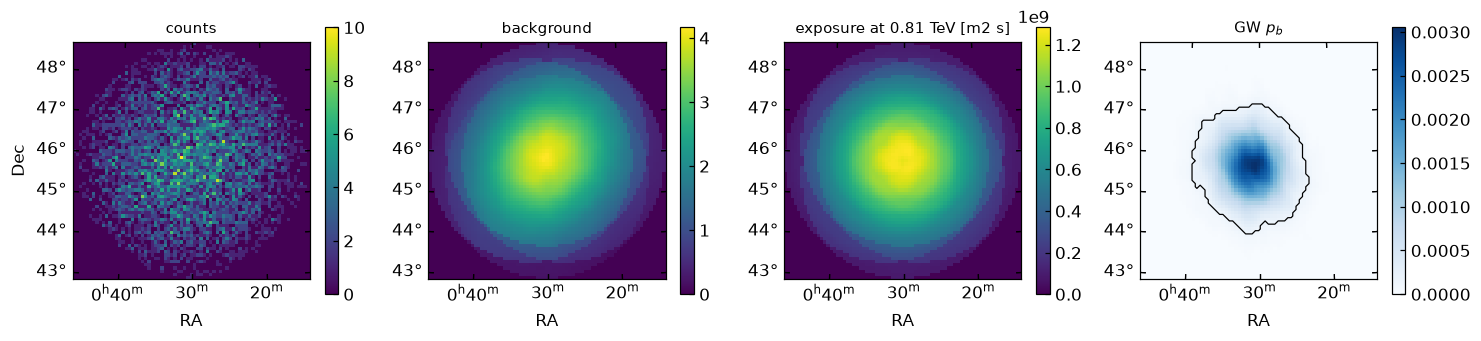

In [ ]:
red = one[0].reduced
ds = red.stacked
e_axis = ds.exposure.geom.axes["energy_true"]
i1 = int(np.argmin(np.abs(e_axis.center.to_value(u.TeV) - 1)))
panels = {"counts": ds.counts.data.sum(axis=0), "background": ds.npred_background().data.sum(axis=0),
          f"exposure at {e_axis.center[i1]:.2f} [m2 s]": ds.exposure.data[i1], "GW $p_b$": one[0].gwmap.prob}
wcs1 = one[0].geom.to_image().wcs
fig, axes = plt.subplots(1, 4, figsize=(16, 4.2), subplot_kw={"projection": wcs1})
for ax, (title, img) in zip(axes, panels.items()):
    im = ax.imshow(img, origin="lower", cmap="Blues" if "GW" in title else "viridis")
    if "GW" in title:
        ax.contour(one[0].gwmap.mask, levels=[0.5], colors="k", linewidths=0.8)
    ax.set_title(title, fontsize=10)
    ax.coords[0].set_axislabel("RA")
    ax.coords[1].set_axislabel("Dec" if ax is axes[0] else " ")
    fig.colorbar(im, ax=ax, shrink=0.75)
figs.save(fig, "wobble_field_maps")
plt.show()

The region of interest of a single-run field, as for one tile of a tiling: the GW 95% region on the field's
grid, the observed region (exposure summed over energy > 0, inside the safe mask), and their intersection, over
which the maximum of $\Lambda$ is taken (`lambda_stat.roi`). Top: run 1 with the `2025_2p5` production; bottom:
the same run with the `2025` production. A bin of the GW region outside the observed region has no data; with
the GW mask alone it entered $\Lambda$ with $TS_b = 0$, a floor $2 \ln p_b$ that does not depend on the data.

2025_2p5: largest 2 ln p_b in the ROI -11.58, outside the observed region none
2025: largest 2 ln p_b in the ROI -11.58, outside the observed region -12.71


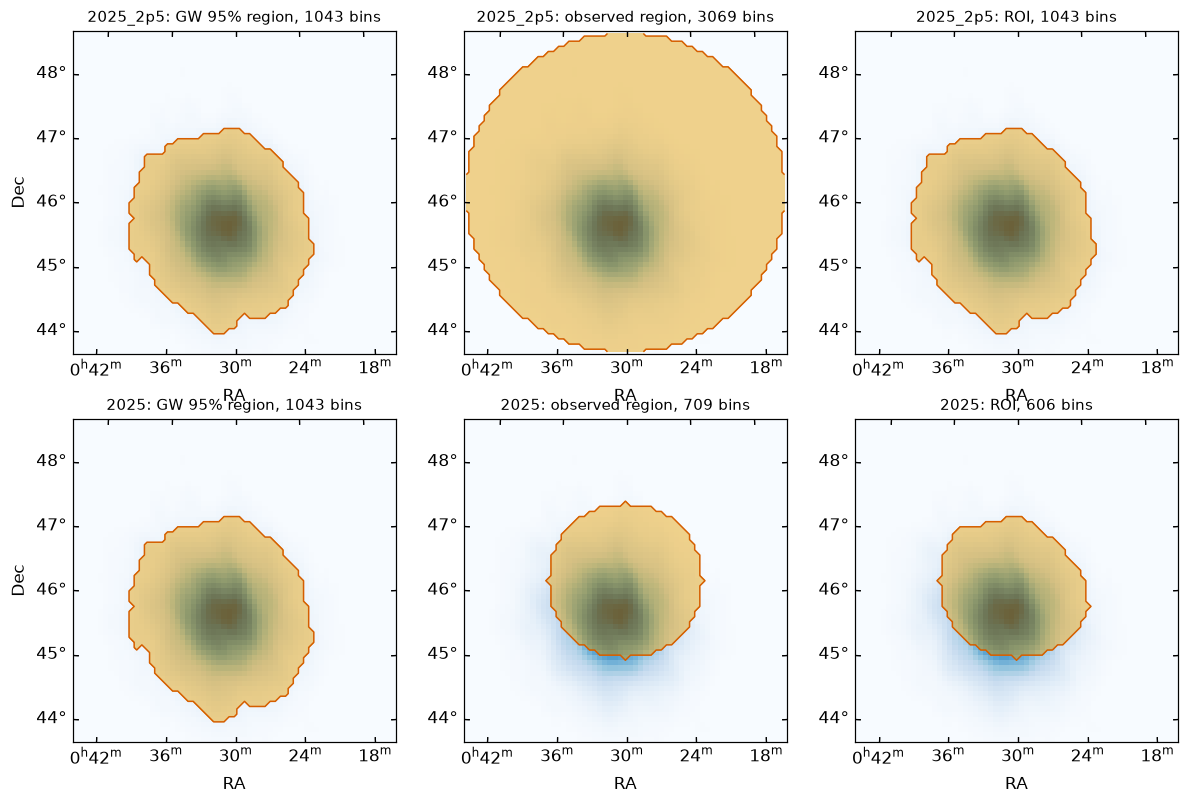

In [ ]:
from uuls import lambda_stat

fig, axes = plt.subplots(2, 3, figsize=(13, 8.4), subplot_kw={"projection": four[0].geom.to_image().wcs})
for row, (label, t) in enumerate((("2025_2p5", four[0]), ("2025", short[0]))):
    obs_region = lambda_stat.observed_region(t.reduced.stacked)
    roi_t = lambda_stat.roi(t.gwmap.mask, t.reduced.stacked)
    for ax, (title, img) in zip(axes[row], {"GW 95% region": t.gwmap.mask, "observed region": obs_region,
                                            "ROI": roi_t}.items()):
        ax.imshow(t.gwmap.prob, origin="lower", cmap="Blues")
        ax.contourf(img, levels=[0.5, 1.5], colors=[COLORS[1]], alpha=0.45)
        ax.contour(img, levels=[0.5], colors=[COLORS[3]], linewidths=1)
        ax.set_title(f"{label}: {title}, {int(img.sum())} bins", fontsize=10)
        ax.coords[0].set_axislabel("RA")
        ax.coords[1].set_axislabel("Dec" if ax is axes[row][0] else " ")
    dark = t.gwmap.mask & ~obs_region
    print(f"{label}: largest 2 ln p_b in the ROI {2 * np.log(t.gwmap.prob[roi_t].max()):.2f}, outside the "
          f"observed region " + (f"{2 * np.log(t.gwmap.prob[dark].max()):.2f}" if dark.any() else "none"))
figs.save(fig, "roi_single_run_field")
plt.show()

Background-only realisations, 2000 each with the same seed (cached), with the ROI (the default) and with the GW
mask alone (`roi="gw_mask"`, the reference behaviour): the four runs as one field and as four, and run 1 alone
with the 1.2 deg exposure. The injector draws on the S240615dg HEALPix map, as it would for a tiling; at
strength zero only the Poisson draws matter. The observed $\Lambda$ of the simulated data is computed with the
same rule and placed in each distribution.

In [ ]:
inj = fields.PWLSkyInjector2D(gwmap.read_healpix(skymap_wob))
N_BKG = 2000
versions = {"one field": one, "four fields": four, "run 1, 1.2 deg exposure": short}
lam, obs = {}, {}
for roi in ("observed", "gw_mask"):
    for label, fs in versions.items():
        lam[roi, label] = realisations.run_fields(fs, inj, np.zeros(N_BKG), seed=61, roi=roi)["lambda"]
        obs[roi, label] = fields.observed_lambda(fs, roi=roi)["lambda"]
rows = []
for (roi, label), x in lam.items():
    q = np.percentile(x, [0, 50, 90, 99])
    rows.append({"version": label, "region": "ROI" if roi == "observed" else "GW mask only", "min": q[0],
                 "median": q[1], "90%": q[2], "99%": q[3], "observed": obs[roi, label],
                 "p-value": np.mean(x >= obs[roi, label])})
lam_table = Table(rows=rows)
lam_table.sort(["version", "region"])
for c in ("min", "median", "90%", "99%", "observed", "p-value"):
    lam_table[c].format = ".2f" if c != "p-value" else ".3f"
lam_table

[cache] realisations_fields/8e1d82c8dd72: loaded
[cache] realisations_fields/4a60fb4555db: loaded
[cache] realisations_fields/d6945e343801: loaded


[cache] realisations_fields/3a82853866f9: loaded
[cache] realisations_fields/fa4eeaa2e8a3: loaded
[cache] realisations_fields/6cd45f1682f2: loaded


version,region,min,median,90%,99%,observed,p-value
str23,str12,float64,float64,float64,float64,float64,float64
four fields,GW mask only,-6.66,-1.59,1.99,6.67,0.56,0.207
four fields,ROI,-6.66,-1.59,1.99,6.67,0.56,0.207
one field,GW mask only,-9.20,-4.04,-0.53,4.36,-6.10,0.867
one field,ROI,-9.20,-4.04,-0.53,4.36,-6.10,0.867
"run 1, 1.2 deg exposure",GW mask only,-8.72,-4.25,-0.77,4.09,0.56,0.050
"run 1, 1.2 deg exposure",ROI,-9.24,-4.67,-1.12,3.38,0.56,0.040


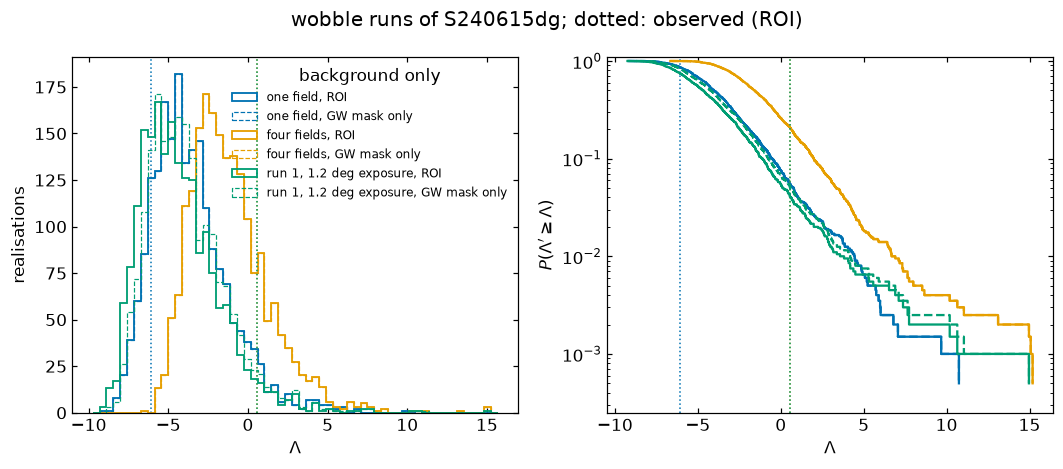

In [ ]:
allx = np.concatenate(list(lam.values()))
bins = np.linspace(allx.min() - 0.5, allx.max() + 0.5, 60)
fig, axs = plt.subplots(1, 2, figsize=(11.5, 4.2))
for label, c in zip(versions, COLORS):
    for roi, ls in (("observed", "-"), ("gw_mask", "--")):
        x = lam[roi, label]
        name = f"{label}, " + ("ROI" if roi == "observed" else "GW mask only")
        axs[0].hist(x, bins, histtype="step", color=c, ls=ls, lw=1.2 if ls == "-" else 0.8, label=name)
        xs = np.sort(x)
        axs[1].step(xs, 1 - np.arange(xs.size) / xs.size, where="post", color=c, ls=ls)
    for ax in axs:
        ax.axvline(obs["observed", label], color=c, ls=":", lw=1)
axs[0].set(xlabel=r"$\Lambda$", ylabel="realisations")
axs[1].set(xlabel=r"$\Lambda$", ylabel=r"$P(\Lambda' \geq \Lambda)$", yscale="log", ylim=(0.5 / N_BKG, 1.1))
axs[0].legend(title="background only", fontsize=8)
fig.suptitle("wobble runs of S240615dg; dotted: observed (ROI)")
figs.save(fig, "lambda_bkg_one_vs_four")
plt.show()

With the `2025_2p5` exposure the observed region of every wobble run covers the whole 95% region of
S240615dg, so the ROI is the GW mask and the two rows of each version coincide. Splitting the four runs into
four fully overlapping fields moves the background distribution of $\Lambda$ up by about 2.5 at the median and
2.3 at the 99% quantile: every position is looked at four times, each time with a quarter of the data. Each
version is calibrated by its own realisations, so the observed $\Lambda$ of the simulated data is an ordinary
background value in both (p-values 0.87 and 0.21 for two different statistics of the same events). The price of
the split shows up for a signal: a source seen by four fields with a quarter of the exposure each is less
significant in each of them than in the combined field, while the background bar is higher. Four fully
overlapping fields is the worst case. In the tiling about a third of the probability lies in two geometries or
more, and now that the exposure reaches 2.5 deg those overlaps are exposed in both fields; this is why fields are
split only at the linking length that separates tiles, not finer.

With the 1.2 deg exposure of the `2025` production, 437 of the 1043 GW-region bins of run 1 have events and a
background estimate but no exposure: no source can produce counts there, yet with the GW mask alone they were
trials. Restricting the maximum to the ROI removes them and lowers the background distribution (median -4.25 to
-4.67, 99% quantile 4.09 to 3.38); the observed $\Lambda$ is the same, because its maximum lies in the observed
part, and its p-value goes from 0.050 to 0.040. Data and realisations use the same ROI in both rows, so each row
is calibrated; the ROI row simply spends no trials where a source cannot be seen.

Outputs: figures `fields_on_sky`, `one_field_gw`, `wobble_field_maps`, `roi_single_run_field` and
`lambda_bkg_one_vs_four` in
`outputs/figures/0_tools/06_fields/`; the GW maps and reductions of every field in `cache/gwmap/` and
`cache/reduce/`, the realisations in `cache/realisations_fields/`.